# 02 · Conversion and reactor sizing: Levenspiel plots

Given rate data as a function of conversion - from a laboratory reactor, not a rate law - how large must the
reactor be, and which kind? Levenspiel's plot of $F_{A0}/(-r_A)$ against $X$ answers both by geometry: the
CSTR volume is a rectangle, the PFR volume the area under the curve. This notebook draws the plot, sizes
reactors, arranges them in series, and shows when a CSTR before a PFR is the right order.

**What you will learn**
- construct Levenspiel plots from rate data
- read CSTR and PFR volumes from them
- size reactors in series and choose their order
- recognise when a CSTR should precede a PFR

**Before you start:** notebook 01  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import ideal, kinetics
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Rate data as a table

  X  -r_A  F_A0/(-r_A) (m3)  V_CSTR (m3)  V_PFR (m3)
0.0 0.450             0.889        0.000       0.000
0.1 0.370             1.081        0.108       0.098
0.2 0.300             1.333        0.267       0.219
0.4 0.195             2.051        0.821       0.558
0.6 0.113             3.540        2.124       1.117
0.7 0.079             5.063        3.544       1.547
0.8 0.050             8.000        6.400       2.200


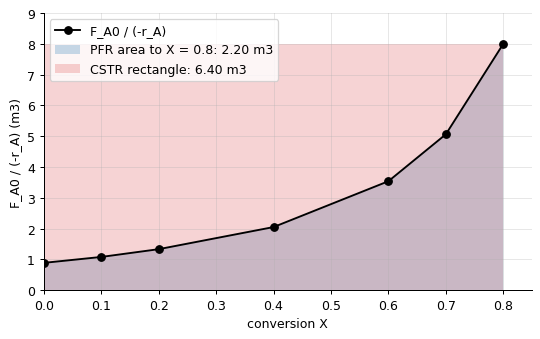

In [2]:
X = np.array([0, 0.1, 0.2, 0.4, 0.6, 0.7, 0.8])
rate = np.array([0.45, 0.37, 0.30, 0.195, 0.113, 0.079, 0.05])     # -r_A in mol/(m3 s), a laboratory table
F_A0 = 0.4                                                          # mol/s
lev = ideal.levenspiel(X, rate, F_A0)
print(pd.DataFrame({"X": X, "-r_A": rate, "F_A0/(-r_A) (m3)": lev["F_over_r"], "V_CSTR (m3)": lev["V_cstr"], "V_PFR (m3)": lev["V_pfr"]}).round(3).to_string(index=False))
fig, ax = plt.subplots()
Xf = np.linspace(0, 0.8, 200)
ax.plot(X, lev["F_over_r"], "ko-", label="F_A0 / (-r_A)")
ax.fill_between(Xf, np.interp(Xf, X, lev["F_over_r"]), alpha=0.25, label=f"PFR area to X = 0.8: {lev['V_pfr'][-1]:.2f} m3")
ax.bar([0.4], [lev["F_over_r"][-1]], width=0.8, alpha=0.2, color="C3", align="center", label=f"CSTR rectangle: {lev['V_cstr'][-1]:.2f} m3")
ax.set(xlabel="conversion X", ylabel="F_A0 / (-r_A) (m3)", xlim=(0, 0.85), ylim=(0, 9)); ax.legend(); plt.show()

The rate falls as conversion rises, so $F_{A0}/(-r_A)$ climbs, and the CSTR - which pays the *final* (lowest)
rate for every mole converted - needs almost three times the PFR volume for 80 % conversion. The plot needs no
rate law: it is the design method for rate data that come as a table.

## Reactors in series

In [3]:
rate_fn = lambda x: np.interp(x, X, rate)
for name, stages in (("CSTR 0.8 m3 then PFR 1.5 m3", [("cstr", 0.8), ("pfr", 1.5)]), ("PFR 1.5 m3 then CSTR 0.8 m3", [("pfr", 1.5), ("cstr", 0.8)]),
                     ("two CSTRs of 1.15 m3", [("cstr", 1.15), ("cstr", 1.15)]), ("one CSTR of 2.3 m3", [("cstr", 2.3)])):
    out = ideal.reactors_in_series(F_A0, stages, rate_fn)
    print(f"{name:<32}: final X = {out[-1]['X_out']:.3f}   (" + ", ".join(f"{s['type']} {s['X_in']:.2f}->{s['X_out']:.2f}" for s in out) + ")")

CSTR 0.8 m3 then PFR 1.5 m3     : final X = 0.788   (cstr 0.00->0.40, pfr 0.40->0.79)
PFR 1.5 m3 then CSTR 0.8 m3     : final X = 0.800   (pfr 0.00->0.70, cstr 0.70->0.80)
two CSTRs of 1.15 m3            : final X = 0.700   (cstr 0.00->0.47, cstr 0.47->0.70)
one CSTR of 2.3 m3              : final X = 0.617   (cstr 0.00->0.62)


For a rate that only falls with conversion, the PFR-first order wins by a hair and two CSTRs beat one of the
same total volume - each stage runs at a higher concentration than a single big tank. Many CSTRs in series
approach a PFR, which is why a cascade of stirred tanks is the industrial way to get plug flow with the
temperature control of a tank.

## When a CSTR should come first

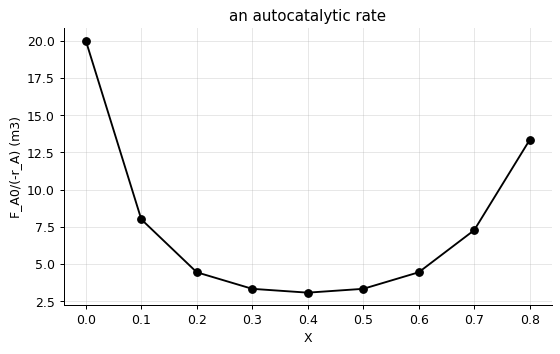

PFR alone to X = 0.8: 5.06 m3; CSTR alone: 10.67 m3
best CSTR (1.25 m3, to X = 0.40) followed by a PFR (2.22 m3): total 3.47 m3


In [4]:
X2 = np.array([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
rate2 = np.array([0.02, 0.05, 0.09, 0.12, 0.13, 0.12, 0.09, 0.055, 0.03])      # autocatalytic: fastest in the middle
lev2 = ideal.levenspiel(X2, rate2, F_A0)
fig, ax = plt.subplots(); ax.plot(X2, lev2["F_over_r"], "ko-"); ax.set(xlabel="X", ylabel="F_A0/(-r_A) (m3)", title="an autocatalytic rate"); plt.show()
from scipy import integrate
rf2 = lambda x: np.interp(x, X2, rate2)
best = None
for V1 in np.linspace(0.5, 6, 23):
    X1 = ideal.reactors_in_series(F_A0, [("cstr", V1)], rf2)[0]["X_out"]
    kinks = [x for x in X2 if X1 < x < 0.8]                                           # the table's breakpoints
    V2 = F_A0 * integrate.quad(lambda x: 1 / rf2(x), X1, 0.8, points=kinks)[0]     # PFR from X1 to 0.8
    if best is None or V1 + V2 < best[0]:
        best = (V1 + V2, V1, X1, V2)
print(f"PFR alone to X = 0.8: {lev2['V_pfr'][-1]:.2f} m3; CSTR alone: {lev2['V_cstr'][-1]:.2f} m3")
print(f"best CSTR ({best[1]:.2f} m3, to X = {best[2]:.2f}) followed by a PFR ({best[3]:.2f} m3): total {best[0]:.2f} m3")

When the rate rises before it falls - autocatalysis, fermentation, some polymerisations - the CSTR should
operate at the maximum rate and a PFR should finish the job: the rectangle sits in the valley of the curve
and the area covers the climb out of it. Levenspiel's geometry makes the choice visible and the optimum
computable.

## From the plot to a rate law

In [5]:
from engreact import rate_data
C_A = 2500.0 * (1 - X)
fit = rate_data.initial_rates_method(C_A[1:], rate[1:])
print(f"the first table looks like a power law of order {fit['order']:.2f} with k = {fit['k']:.2e}; a first-order fit gives k = {np.mean(rate[:-1]/C_A[:-1]):.2e} 1/s")

the first table looks like a power law of order 1.33 with k = 1.21e-05; a first-order fit gives k = 1.40e-04 1/s


Levenspiel plots do not need a rate law, but a rate law lets you extrapolate, change temperature and design
for conditions not in the table. The next notebook builds rate laws; notebook 05 extracts them from data.

## Inside the algorithm: trapezoidal area under the Levenspiel curve

In [6]:
y = F_A0 / rate
area = sum(0.5 * (y[i] + y[i + 1]) * (X[i + 1] - X[i]) for i in range(len(X) - 1))
print("by hand: PFR volume", round(area, 3), "m3; library:", round(lev["V_pfr"][-1], 3))

by hand: PFR volume 2.2 m3; library: 2.2


## Exercises
1. Using the first rate table, find the minimum total volume of two CSTRs in series reaching X = 0.8 by scanning the intermediate conversion, and compare with a single CSTR and with a PFR.
2. Fit the first rate table to -r_A = k C_A (C_A = C_A0 (1 - X)) and recompute the PFR and CSTR volumes from the rate law instead of the table. How much do they differ from the trapezoidal areas, and why?
3. **Implement it yourself:** write `cstr_series(F_A0, volumes, rate_fn)` that solves each stage's balance with brentq and reproduces `ideal.reactors_in_series` for two CSTRs.